# Лабораторная 2. Обучение диалоговых моделей
**Qwen2.5-0.5B-Instruct + LoRA** и **FLAN-T5-small + полное дообучение**.


## 1. Подготовка окружения

In [5]:
import gc
import torch

for name in [
    "qwen", "q_trainer", "t5", "t_trainer", "t_collator",
    "model", "trainer", "optimizer",
]:
    globals().pop(name, None)

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    free, total = torch.cuda.mem_get_info()
    print(f"Свободно VRAM: {free / 2**30:.2f} из {total / 2**30:.2f} ГБ")
else:
    print("CUDA недоступна")

Свободно VRAM: 6.93 из 8.00 ГБ


In [1]:
import sys, subprocess, importlib.util

if importlib.util.find_spec("torch") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch>=2.6,<3"])

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "transformers==4.57.1", "datasets==4.1.1", "peft==0.17.1",
    "accelerate==1.10.1", "evaluate==0.4.6", "sacrebleu==2.5.1",
    "nltk==3.9.1", "sentencepiece==0.2.1", "protobuf",
    "pandas", "matplotlib", "tqdm", "ipywidgets",
])

0

In [2]:
import os, gc, json, re, hashlib, unicodedata, time
from pathlib import Path
from itertools import combinations
from contextlib import nullcontext
from importlib.metadata import version

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["WANDB_DISABLED"] = "true"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, transformers, datasets, peft, accelerate, evaluate, nltk
from IPython.display import display
from tqdm.auto import tqdm
from datasets import load_dataset, Dataset
from transformers import (
    AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq, Trainer, TrainingArguments, GenerationConfig, set_seed,
)
from peft import LoraConfig, get_peft_model, PeftModel
from sacrebleu.metrics import BLEU
from nltk.translate.meteor_score import meteor_score
from nltk.tokenize import word_tokenize

packages = ["torch", "transformers", "datasets", "peft", "accelerate",
            "evaluate", "sacrebleu", "nltk", "numpy", "pandas"]
versions = {p: version(p) for p in packages}
display(pd.Series(versions, name="version").to_frame())

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = (DEVICE == "cuda" and torch.cuda.get_device_capability(0)[0] >= 8
        and torch.cuda.is_bf16_supported())  # Аппаратная поддержка, без эмуляции на T4.
QWEN_AMP = (torch.bfloat16 if BF16 else torch.float16) if DEVICE == "cuda" else None
T5_AMP = torch.bfloat16 if BF16 else None  # T5 на T4 обучаем в FP32: без FP16 overflow.
print("Устройство:", DEVICE, "| BF16:", BF16)
if DEVICE == "cuda":
    free, total = torch.cuda.mem_get_info()
    print(torch.cuda.get_device_name(0))
    print(f"VRAM: свободно {free / 2**30:.1f} / всего {total / 2**30:.1f} ГБ")
else:
    print("Для полного эксперимента включите GPU в настройках ноутбука.")

,version
torch,2.7.1+cu118
transformers,4.57.1
datasets,4.1.1
peft,0.17.1
accelerate,1.10.1
evaluate,0.4.6
sacrebleu,2.5.1
nltk,3.9.1
numpy,2.3.5
pandas,3.0.0


Устройство: cuda | BF16: True
NVIDIA GeForce RTX 4060 Laptop GPU
VRAM: свободно 6.9 / всего 8.0 ГБ


In [3]:
SEED = 42
N_TRAIN, N_VAL, N_TEST = 6000, 400, 400
EPOCHS = 2
HISTORY_TURNS = 3
MAX_INPUT, MAX_NEW_TOKENS = 192, 64
GEN_BATCH = 8 
RUN_TEST = False
OUT = Path("lab2_results")
OUT.mkdir(parents=True, exist_ok=True)
set_seed(SEED)

QWEN_ID = "Qwen/Qwen2.5-0.5B-Instruct"
QWEN_REV = "7ae557604adf67be50417f59c2c2f167def9a775"
T5_ID = "google/flan-t5-small"
T5_REV = "0fc9ddf78a1e988dac52e2dac162b0ede4fd74ab"
DATA_ID = "li2017dailydialog/daily_dialog"
DATA_REV = "469b7118f52336674f1d78693797e9fcc7e47d2a"  # Parquet snapshot
GEN = dict(max_new_tokens=MAX_NEW_TOKENS, do_sample=False, num_beams=1,
           repetition_penalty=1.0, use_cache=True)

def save_json(obj, path):
    Path(path).write_text(json.dumps(obj, ensure_ascii=False, indent=2), encoding="utf-8")

def release_memory():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

def amp_context(family):
    dtype = QWEN_AMP if family == "qwen" else T5_AMP
    return torch.autocast("cuda", dtype=dtype) if dtype else nullcontext()

## 2. Загрузка и исследование DailyDialog

In [6]:
from huggingface_hub import hf_hub_download
from datasets import load_dataset

files = {}

for split in ["train", "validation", "test"]:
    files[split] = hf_hub_download(
        repo_id=DATA_ID,
        repo_type="dataset",
        revision=DATA_REV,
        filename=f"default/{split}/0000.parquet",
    )
    print(f"{split}: скачано")

raw = load_dataset("parquet", data_files=files)
print(raw)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


0000.parquet:   0%|          | 0.00/3.61M [00:00<?, ?B/s]

C:\Users\Александр\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Александр\.cache\huggingface\hub\datasets--li2017dailydialog--daily_dialog. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


train: скачано


0000.parquet:   0%|          | 0.00/334k [00:00<?, ?B/s]

validation: скачано


... (2 outputs left out)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['dialog', 'act', 'emotion'],
        num_rows: 11118
    })
    validation: Dataset({
        features: ['dialog', 'act', 'emotion'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['dialog', 'act', 'emotion'],
        num_rows: 1000
    })
})


In [7]:
def clean_text(text):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFKC", text)).strip()

def text_key(text):
    return " ".join(re.findall(r"\w+|[^\w\s]", clean_text(text).casefold()))

def fingerprint(parts):
    data = json.dumps(parts, ensure_ascii=False).encode("utf-8")
    return hashlib.sha256(data).hexdigest()

def bad_text(text):
    return (not isinstance(text, str) or not text.strip()
            or "\ufffd" in text or any(ord(c) < 32 and not c.isspace() for c in text))

dialog_rows, quality_rows = {}, []
for split, ds in raw.items():
    rows, utterances = [], []
    for i, item in enumerate(ds):
        turns = item["dialog"]
        utterances.extend(turns)
        if len(turns) < 2 or any(bad_text(t) for t in turns):
            continue 
        turns = [clean_text(t) for t in turns]
        rows.append(dict(split=split, dialog_id=f"{split}:{i}", turns=turns,
                         dialog_hash=fingerprint([text_key(t) for t in turns])))
    dialog_rows[split] = rows
    quality_rows.append({
        "split": split, "диалогов": len(ds), "реплик": len(utterances),
        "реплик/диалог": round(len(utterances) / len(ds), 2),
        "плохих реплик": sum(bad_text(t) for t in utterances),
        "отброшено диалогов": len(ds) - len(rows),
        "копий диалогов": len(rows) - len({r["dialog_hash"] for r in rows}),
        "копий реплик": len(utterances) - len({text_key(t) for t in utterances if isinstance(t, str)}),
        "ошибок разметки": sum(len(x["dialog"]) != len(x["act"]) or
                              len(x["dialog"]) != len(x["emotion"]) for x in ds),
    })
quality = pd.DataFrame(quality_rows)
display(quality)
quality.to_csv(OUT / "data_quality.csv", index=False)

,split,диалогов,реплик,реплик/диалог,плохих реплик,отброшено диалогов,копий диалогов,копий реплик,ошибок разметки
0,train,11118,87170,7.84,0,0,732,16717,0
1,validation,1000,8069,8.07,0,0,5,434,0
2,test,1000,7740,7.74,0,0,4,304,0


,count,mean,std,min,50%,90%,99%,max
split,,,,,,,,
test,7740.0,13.8,10.4,2.0,11.0,26.0,52.6,204.0
train,87170.0,13.6,10.3,1.0,11.0,26.0,51.0,278.0
validation,8069.0,13.5,10.0,1.0,11.0,25.0,49.3,166.0


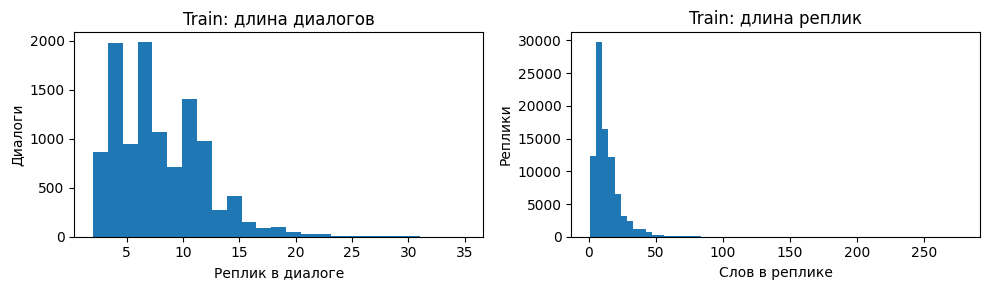

In [8]:
lengths = pd.DataFrame([
    {"split": split, "реплик": len(r["turns"]),
     "слов в реплике": len(text.split())}
    for split, rows in dialog_rows.items() for r in rows for text in r["turns"]
])
display(lengths.groupby("split")["слов в реплике"].describe(percentiles=[.5, .9, .99]).round(1))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist([len(r["turns"]) for r in dialog_rows["train"]], bins=25)
axes[0].set(xlabel="Реплик в диалоге", ylabel="Диалоги", title="Train: длина диалогов")
axes[1].hist(lengths.loc[lengths.split == "train", "слов в реплике"], bins=60)
axes[1].set(xlabel="Слов в реплике", ylabel="Реплики", title="Train: длина реплик")
fig.tight_layout()
fig.savefig(OUT / "data_lengths.png", dpi=150)
plt.show()

## 3. Единый экспериментальный набор

In [9]:
overlaps = []
for a, b in combinations(dialog_rows, 2):
    shared = {r["dialog_hash"] for r in dialog_rows[a]} & {r["dialog_hash"] for r in dialog_rows[b]}
    overlaps.append({"splits": f"{a} / {b}", "совпадений диалогов до очистки": len(shared)})
display(pd.DataFrame(overlaps))

seen_dialogs, unique_dialogs = set(), {}
for split in ["test", "validation", "train"]:
    unique_dialogs[split] = []
    for r in dialog_rows[split]:
        if r["dialog_hash"] not in seen_dialogs:
            unique_dialogs[split].append(r)
            seen_dialogs.add(r["dialog_hash"])

INSTRUCTION = "Continue the conversation in English. Write only B's next reply, briefly and naturally."

def make_pairs(rows):
    pairs = []
    for r in rows:
        turns = r["turns"]
        for j in range(1, len(turns), 2):
            context = "\n".join(f"{'A' if k % 2 == 0 else 'B'}: {turns[k]}"
                                for k in range(max(0, j - HISTORY_TURNS), j))
            pairs.append({
                "pair_id": f"{r['dialog_id']}:{j}", "dialog_id": r["dialog_id"],
                "dialog_hash": r["dialog_hash"], "context": context, "reply": turns[j],
                "prompt": f"{INSTRUCTION}\n\n{context}\nB:",
                "context_hash": fingerprint([text_key(context)]),
                "pair_hash": fingerprint([text_key(turns[j - 1]), text_key(turns[j])]),
            })
    return pd.DataFrame(pairs)

seen_pairs, seen_contexts, pools, counts = set(), set(), {}, []
for split in ["test", "validation", "train"]:
    frame = make_pairs(unique_dialogs[split])
    before = len(frame)
    frame = frame.drop_duplicates("pair_hash").drop_duplicates("context_hash")
    frame = frame[~frame.pair_hash.isin(seen_pairs) & ~frame.context_hash.isin(seen_contexts)]
    seen_pairs.update(frame.pair_hash)
    seen_contexts.update(frame.context_hash)
    pools[split] = frame.reset_index(drop=True)
    counts.append({"split": split, "пар до очистки": before, "пар после очистки": len(frame)})
display(pd.DataFrame(counts))

,splits,совпадений диалогов до очистки
0,train / validation,93
1,train / test,123
2,validation / test,5


,split,пар до очистки,пар после очистки
0,test,3688,3660
1,validation,3808,3695
2,train,38166,34390


In [10]:
q_tok = AutoTokenizer.from_pretrained(QWEN_ID, revision=QWEN_REV)
t_tok = AutoTokenizer.from_pretrained(T5_ID, revision=T5_REV)
q_tok.padding_side = "right"
if q_tok.pad_token_id is None:
    q_tok.pad_token = q_tok.eos_token

def qwen_prompt_ids(prompt):
    return q_tok.apply_chat_template(
        [{"role": "user", "content": prompt}], tokenize=True, add_generation_prompt=True,
    )

filtered, length_stats = {}, []
for split, frame in pools.items():
    prompts, replies = frame.prompt.tolist(), frame.reply.tolist()
    q_inputs = [len(qwen_prompt_ids(p)) for p in tqdm(prompts, desc=f"Длины: {split}")]
    q_targets = [len(x) + 1 for x in q_tok(replies, add_special_tokens=False)["input_ids"]]
    t_inputs = [len(x) for x in t_tok(prompts)["input_ids"]]
    t_targets = [len(x) for x in t_tok(text_target=replies)["input_ids"]]
    keep = ((np.array(q_inputs) <= MAX_INPUT) & (np.array(t_inputs) <= MAX_INPUT)
            & (np.array(q_targets) <= MAX_NEW_TOKENS) & (np.array(t_targets) <= MAX_NEW_TOKENS))
    filtered[split] = frame.loc[keep].reset_index(drop=True)
    length_stats.append({"split": split, "до": len(frame), "после": int(keep.sum()),
                         "отброшено, %": round(100 * (1 - keep.mean()), 2)})
display(pd.DataFrame(length_stats))

tokenizer_config.json: 0.00B [00:00, ?B/s]

C:\Users\Александр\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Александр\.cache\huggingface\hub\models--Qwen--Qwen2.5-0.5B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

... (4 outputs left out)

Длины: test:   0%|          | 0/3660 [00:00<?, ?it/s]

Длины: validation:   0%|          | 0/3695 [00:00<?, ?it/s]

Длины: train:   0%|          | 0/34390 [00:00<?, ?it/s]

,split,до,после,"отброшено, %"
0,test,3660,3593,1.83
1,validation,3695,3641,1.46
2,train,34390,33837,1.61


In [11]:
sizes = {"train": N_TRAIN, "validation": N_VAL, "test": N_TEST}
fixed = {}
for split, n in sizes.items():
    assert len(filtered[split]) >= n, f"Недостаточно пар в {split}"
    fixed[split] = filtered[split].sample(n=n, random_state=SEED).reset_index(drop=True)

for a, b in combinations(fixed, 2):
    for key in ["dialog_id", "dialog_hash", "pair_hash", "context_hash"]:
        assert set(fixed[a][key]).isdisjoint(fixed[b][key]), (a, b, key)

for split, frame in fixed.items():
    frame.to_json(OUT / f"{split}.jsonl", orient="records", lines=True, force_ascii=False)
train_df, val_df = fixed["train"], fixed["validation"]
print({s: len(f) for s, f in fixed.items()})
print("Пересечения ID, диалогов, пар и контекстов: 0")
print(train_df.iloc[0].prompt, "\n\nЭталон:", train_df.iloc[0].reply)

config = dict(seed=SEED, sizes=sizes, epochs=EPOCHS, history_turns=HISTORY_TURNS,
              max_input=MAX_INPUT, generation=GEN, generation_batch=GEN_BATCH,
              instruction=INSTRUCTION, dataset=DATA_ID, dataset_revision=DATA_REV,
              qwen=QWEN_ID, qwen_revision=QWEN_REV, t5=T5_ID, t5_revision=T5_REV,
              versions=versions, device=DEVICE, bf16=BF16,
              sample_hashes={s: hashlib.sha256((OUT / f"{s}.jsonl").read_bytes()).hexdigest()
                             for s in sizes})
save_json(config, OUT / "config.json")

{'train': 6000, 'validation': 400, 'test': 400}
Пересечения ID, диалогов, пар и контекстов: 0
Continue the conversation in English. Write only B's next reply, briefly and naturally.

A: I really need to get some things before I leave .
B: Well , you could go down to 22nd street . There are lot of stores down there that are open 24 hours a day .
A: Can I take the subway to get there ?
B: 

Эталон: Yes , but that'll probably take about half an hour . You should just take a cab .


In [12]:
for resource in ["wordnet", "omw-1.4"]:
    assert nltk.download(resource, quiet=True), f"Не удалось скачать NLTK {resource}"

bleu_metric = BLEU(max_ngram_order=4, tokenize="13a", lowercase=False,
                   smooth_method="exp", effective_order=False)

def score_answers(predictions, references):
    assert len(predictions) == len(references) > 0
    predictions = [clean_text(p) for p in predictions]
    references = [clean_text(r) for r in references]
    bleu = bleu_metric.corpus_score(predictions, [references]).score
    meteor = np.mean([
        meteor_score([word_tokenize(r, preserve_line=True)], word_tokenize(p, preserve_line=True))
        for p, r in zip(predictions, references)
    ]) * 100
    return {"BLEU-4": float(bleu), "METEOR": float(meteor),
            "empty_%": 100 * sum(not p for p in predictions) / len(predictions)}

@torch.inference_mode()
def generate_answers(model, tokenizer, frame, family):
    model.eval()
    old_side = tokenizer.padding_side
    tokenizer.padding_side = "left" if family == "qwen" else "right"
    cfg = GenerationConfig(**GEN, pad_token_id=tokenizer.pad_token_id,
                           eos_token_id=tokenizer.eos_token_id,
                           decoder_start_token_id=getattr(model.config, "decoder_start_token_id", None))
    predictions = []
    try:
        for start in tqdm(range(0, len(frame), GEN_BATCH), desc=f"Генерация: {family}"):
            prompts = frame.prompt.iloc[start:start + GEN_BATCH].tolist()
            if family == "qwen":
                ids = [qwen_prompt_ids(p) for p in prompts]
                batch = tokenizer.pad({"input_ids": ids}, padding=True, return_tensors="pt")
            else:
                batch = tokenizer(prompts, padding=True, return_tensors="pt")
            assert batch["input_ids"].shape[1] <= MAX_INPUT
            batch = batch.to(DEVICE)
            with amp_context(family):
                output = model.generate(**batch, generation_config=cfg)
            if family == "qwen":
                output = output[:, batch["input_ids"].shape[1]:]  # Только новые токены.
            predictions.extend(tokenizer.batch_decode(output, skip_special_tokens=True))
    finally:
        tokenizer.padding_side = old_side
    return [clean_text(p) for p in predictions]

results = []
def evaluate_and_save(model, tokenizer, frame, family, stage, split="validation"):
    started = time.perf_counter()
    predictions = generate_answers(model, tokenizer, frame, family)
    table = frame[["pair_id", "context", "reply"]].copy()
    table["prediction"] = predictions
    table.to_csv(OUT / f"{family}_{stage}_{split}.csv", index=False)
    row = dict(model=family, stage=stage, split=split, n=len(frame),
               **score_answers(predictions, frame.reply.tolist()),
               seconds=round(time.perf_counter() - started, 1))
    results[:] = [r for r in results if (r["model"], r["stage"], r["split"]) != (family, stage, split)]
    results.append(row)
    pd.DataFrame(results).to_csv(OUT / "metrics.csv", index=False)
    save_json({"sacrebleu_signature": str(bleu_metric.get_signature()),
               "meteor": "mean NLTK METEOR * 100; word_tokenize(preserve_line=True)"},
              OUT / "metric_config.json")
    display(pd.DataFrame([row]).round(3))
    return table

## 4. Zero-shot Qwen
Сначала смотрим три ответа, затем оцениваем все 400 пар. Greedy decoding: без случайного сэмплирования.

In [13]:
set_seed(SEED)
qwen = AutoModelForCausalLM.from_pretrained(
    QWEN_ID, revision=QWEN_REV, dtype=torch.float32,
    attn_implementation="sdpa", use_safetensors=True,
).to(DEVICE)
preview = val_df[["context", "reply"]].head(3).copy()
preview["Qwen zero-shot"] = generate_answers(qwen, q_tok, val_df.head(3), "qwen")
display(preview)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Генерация: qwen:   0%|          | 0/1 [00:00<?, ?it/s]

You're using a Qwen2TokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


,context,reply,Qwen zero-shot
0,A: I ’ m a new student . My name ’ s Robert .\...,"Yes , I ’ m . Are you French , too ?","A: Yes, I am French. Nice to meet you too."
1,"A: Well , it's really none of your business .\...",Fine .,"I'm sorry, but I have to go."
2,"A: Excuse me , is this the Auto Consumer Loan ...",Yes . Is there anything I can do for you ?,"A: Yes, it is. I'm here to inquire about the A..."


In [14]:
qwen_before = evaluate_and_save(qwen, q_tok, val_df, "qwen", "before")

Генерация: qwen:   0%|          | 0/50 [00:00<?, ?it/s]

,model,stage,split,n,BLEU-4,METEOR,empty_%,seconds
0,qwen,before,validation,400,1.267,15.239,0.0,56.3


## 5. Qwen: две эпохи SFT через LoRA
`input_ids = запрос + ответ + EOS`; `labels = −100 для запроса, токены ответа и EOS`.
Сдвиг labels для предсказания следующего токена выполняет модель. Padding тоже исключён из loss.

In [15]:
def qwen_example(row):
    prompt = qwen_prompt_ids(row["prompt"])
    answer = q_tok(row["reply"], add_special_tokens=False)["input_ids"] + [q_tok.eos_token_id]
    return {"input_ids": prompt + answer, "attention_mask": [1] * (len(prompt) + len(answer)),
            "labels": [-100] * len(prompt) + answer}

q_train = Dataset.from_list([qwen_example(r) for r in train_df.to_dict("records")])
q_val = Dataset.from_list([qwen_example(r) for r in val_df.to_dict("records")])
q_collator = DataCollatorForSeq2Seq(q_tok, model=None, label_pad_token_id=-100, pad_to_multiple_of=8)

example = q_train[0]
prompt_len = len(qwen_prompt_ids(train_df.iloc[0].prompt))
assert all(x == -100 for x in example["labels"][:prompt_len])
assert example["labels"][prompt_len:] == example["input_ids"][prompt_len:]
assert example["labels"][-1] == q_tok.eos_token_id
batch = q_collator([q_train[0], q_train[1]])
assert torch.all(batch["labels"][batch["attention_mask"] == 0] == -100)
print("Текст, по которому считается loss:")
print(q_tok.decode([x for x in example["labels"] if x != -100]))

Текст, по которому считается loss:
Yes , but that'll probably take about half an hour . You should just take a cab .<|im_end|>


In [16]:
set_seed(SEED)
qwen = get_peft_model(qwen, LoraConfig(
    task_type="CAUSAL_LM", revision=QWEN_REV, r=16, lora_alpha=32, lora_dropout=0.05,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj"], bias="none",
))
qwen.print_trainable_parameters()
qwen.config.use_cache = False
assert all("lora_" in name for name, p in qwen.named_parameters() if p.requires_grad)

trainable params: 2,162,688 || all params: 496,195,456 || trainable%: 0.4359


`AdamW` обновляет веса; scheduler меняет learning rate: 5% шагов разогрева, затем линейное снижение.
Эффективный batch = 32. После двух эпох сохраняем checkpoint с минимальным validation loss.

In [17]:
def training_args(family, batch_size, accumulation, learning_rate):
    return TrainingArguments(
        output_dir=str(OUT / f"{family}_checkpoints"),
        num_train_epochs=EPOCHS, learning_rate=learning_rate,
        per_device_train_batch_size=batch_size, gradient_accumulation_steps=accumulation,
        per_device_eval_batch_size=4, optim="adamw_torch", weight_decay=0.01,
        lr_scheduler_type="linear", warmup_ratio=0.05, max_grad_norm=1.0,
        bf16=BF16, fp16=(family == "qwen" and DEVICE == "cuda" and not BF16),
        gradient_checkpointing=(family == "qwen"),
        gradient_checkpointing_kwargs={"use_reentrant": False},
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=2,
        load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
        prediction_loss_only=True, logging_steps=20, logging_nan_inf_filter=False,
        report_to="none", seed=SEED, data_seed=SEED, dataloader_num_workers=0,
        dataloader_pin_memory=(DEVICE == "cuda"), label_names=["labels"],
    )

q_trainer = Trainer(
    model=qwen, args=training_args("qwen", batch_size=4, accumulation=8, learning_rate=2e-4),
    train_dataset=q_train, eval_dataset=q_val, data_collator=q_collator, processing_class=q_tok,
)
q_initial_loss = q_trainer.evaluate()["eval_loss"]
assert np.isfinite(q_initial_loss)
q_training = q_trainer.train() 
q_trainer.save_model(str(OUT / "qwen_lora"))
q_tok.save_pretrained(OUT / "qwen_lora")
save_json(q_trainer.state.log_history, OUT / "qwen_loss.json")
save_json(dict(q_training.metrics, best_checkpoint=q_trainer.state.best_model_checkpoint,
               best_eval_loss=q_trainer.state.best_metric), OUT / "qwen_training.json")
print("Лучший validation loss:", q_trainer.state.best_metric)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Epoch,Training Loss,Validation Loss,Model Preparation Time
1,2.427700,2.318033,0.008600
2,2.281900,2.312960,0.008600


Лучший validation loss: 2.312959671020508


## 6. Qwen после обучения
Те же пары, шаблон запроса, precision и параметры генерации.

In [18]:
qwen.gradient_checkpointing_disable()
qwen.config.use_cache = True
qwen_after = evaluate_and_save(qwen, q_tok, val_df, "qwen", "after")

Генерация: qwen:   0%|          | 0/50 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,model,stage,split,n,BLEU-4,METEOR,empty_%,seconds
0,qwen,after,validation,400,2.22,15.82,0.0,35.3


In [19]:
del q_trainer, qwen
release_memory()

## 7. Zero-shot FLAN-T5
Текст инструкции тот же. Вход передаётся encoder, ответ генерирует decoder.

In [20]:
set_seed(SEED)
t5 = AutoModelForSeq2SeqLM.from_pretrained(
    T5_ID, revision=T5_REV, dtype=torch.float32, use_safetensors=True,
).to(DEVICE)
preview = val_df[["context", "reply"]].head(3).copy()
preview["FLAN-T5 zero-shot"] = generate_answers(t5, t_tok, val_df.head(3), "t5")
display(preview)

config.json: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/308M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Генерация: t5:   0%|          | 0/1 [00:00<?, ?it/s]

,context,reply,FLAN-T5 zero-shot
0,A: I ’ m a new student . My name ’ s Robert .\...,"Yes , I ’ m . Are you French , too ?",I am French .
1,"A: Well , it's really none of your business .\...",Fine .,"I'm sorry , but I have to go ."
2,"A: Excuse me , is this the Auto Consumer Loan ...",Yes . Is there anything I can do for you ?,"No , it is the Auto Consumer Loan Center."


In [21]:
t5_before = evaluate_and_save(t5, t_tok, val_df, "t5", "before")

Генерация: t5:   0%|          | 0/50 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,model,stage,split,n,BLEU-4,METEOR,empty_%,seconds
0,t5,before,validation,400,1.421,10.915,0.0,11.8


## 8. FLAN-T5: полное дообучение
Encoder получает запрос, `labels` содержат ответ. При teacher forcing decoder видит предыдущие **эталонные** токены.
Сдвиг decoder input выполняется автоматически; обновляются все веса.

In [22]:
def t5_example(row):
    item = t_tok(row["prompt"])
    item["labels"] = t_tok(text_target=row["reply"])["input_ids"]
    return item

t_train = Dataset.from_list([t5_example(r) for r in train_df.to_dict("records")])
t_val = Dataset.from_list([t5_example(r) for r in val_df.to_dict("records")])
t_collator = DataCollatorForSeq2Seq(t_tok, model=t5, label_pad_token_id=-100, pad_to_multiple_of=8)
assert all(p.requires_grad for p in t5.parameters())
print(f"Обучаемых параметров: {sum(p.numel() for p in t5.parameters()):,}")
batch = t_collator([t_train[0], t_train[1]])
assert torch.all(batch["decoder_input_ids"][:, 0] == t5.config.decoder_start_token_id)
print("Encoder:", t_tok.decode(t_train[0]["input_ids"]))
print("Labels:", t_tok.decode(t_train[0]["labels"]))

Обучаемых параметров: 76,961,152
Encoder: Continue the conversation in English. Write only B's next reply, briefly and naturally. A: I really need to get some things before I leave . B: Well , you could go down to 22nd street . There are lot of stores down there that are open 24 hours a day . A: Can I take the subway to get there ? B:</s>
Labels: Yes , but that'll probably take about half an hour . You should just take a cab .</s>


In [23]:
set_seed(SEED)
t5.config.use_cache = False
t_trainer = Trainer(
    model=t5, args=training_args("t5", batch_size=8, accumulation=4, learning_rate=5e-5),
    train_dataset=t_train, eval_dataset=t_val, data_collator=t_collator, processing_class=t_tok,
)
t_initial_loss = t_trainer.evaluate()["eval_loss"]
assert np.isfinite(t_initial_loss)
t_training = t_trainer.train()
t_trainer.save_model(str(OUT / "flan_t5"))
t_tok.save_pretrained(OUT / "flan_t5")
save_json(t_trainer.state.log_history, OUT / "t5_loss.json")
save_json(dict(t_training.metrics, best_checkpoint=t_trainer.state.best_model_checkpoint,
               best_eval_loss=t_trainer.state.best_metric), OUT / "t5_training.json")
print("Лучший validation loss:", t_trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Model Preparation Time
1,2.670100,2.373662,0.003000
2,2.549200,2.362238,0.003000


There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight'].


Лучший validation loss: 2.3622379302978516


## 9. FLAN-T5 после обучения
Генерация без teacher forcing; настройки совпадают с zero-shot.

In [24]:
t5.config.use_cache = True
t5_after = evaluate_and_save(t5, t_tok, val_df, "t5", "after")

Генерация: t5:   0%|          | 0/50 [00:00<?, ?it/s]

That's 100 lines that end in a tokenized period ('.')
It looks like you forgot to detokenize your test data, which may hurt your score.
If you insist your data is detokenized, or don't care, you can suppress this message with the `force` parameter.


,model,stage,split,n,BLEU-4,METEOR,empty_%,seconds
0,t5,after,validation,400,1.659,13.199,0.0,12.9


In [25]:
del t_trainer, t_collator, t5
release_memory()

## 10. Сравнение, графики и отчёт
Сравниваем эффект обучения внутри каждой модели. Это не чистый эксперимент над архитектурами:
различаются размер моделей, предобучение и способ обновления весов. Loss разных токенизаторов напрямую не сравниваем.

,model,stage,n,BLEU-4,METEOR,empty_%,seconds
0,qwen,before,400,1.267,15.239,0.0,56.3
1,qwen,after,400,2.220,15.820,0.0,35.3
2,t5,before,400,1.421,10.915,0.0,11.8
3,t5,after,400,1.659,13.199,0.0,12.9


Изменение после обучения (пункты):


,BLEU-4,METEOR
model,,
qwen,0.953,0.581
t5,0.238,2.284


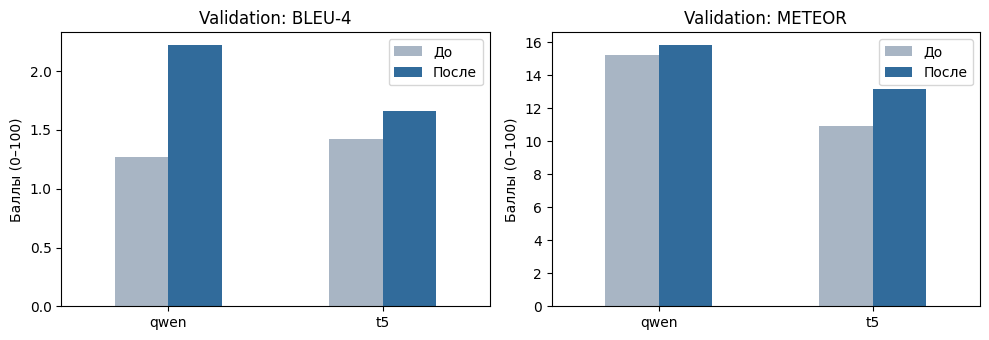

In [26]:
metrics = pd.read_csv(OUT / "metrics.csv")
validation = metrics[metrics.split == "validation"].copy()
display(validation[["model", "stage", "n", "BLEU-4", "METEOR", "empty_%", "seconds"]].round(3))
wide = validation.pivot(index="model", columns="stage", values=["BLEU-4", "METEOR"])
delta = pd.DataFrame({m: wide[m]["after"] - wide[m]["before"] for m in ["BLEU-4", "METEOR"]})
print("Изменение после обучения (пункты):")
display(delta.round(3))
delta.to_csv(OUT / "metric_deltas.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, metric in zip(axes, ["BLEU-4", "METEOR"]):
    wide[metric][["before", "after"]].plot.bar(ax=ax, rot=0, color=["#a8b5c4", "#316b9b"])
    ax.set(title=f"Validation: {metric}", ylabel="Баллы (0–100)", xlabel="")
    ax.legend(["До", "После"])
fig.tight_layout()
fig.savefig(OUT / "metrics.png", dpi=150)
plt.show()

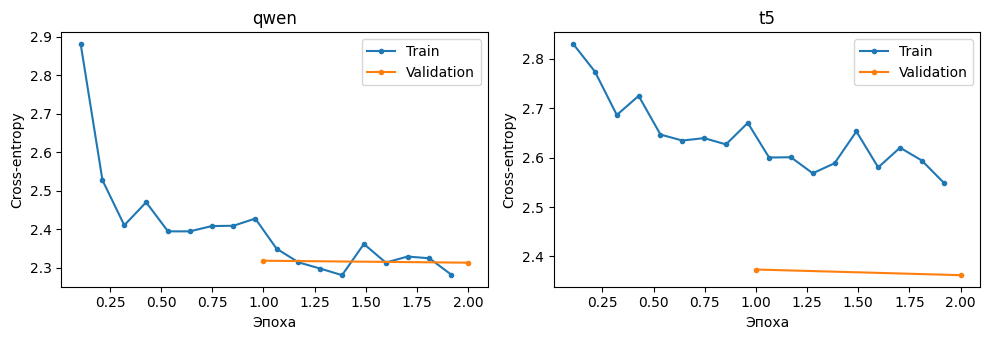

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, family in zip(axes, ["qwen", "t5"]):
    history = pd.read_json(OUT / f"{family}_loss.json")
    history["epoch"] = history["epoch"].fillna(0)
    for column, label in [("loss", "Train"), ("eval_loss", "Validation")]:
        points = history.dropna(subset=[column])
        assert np.isfinite(points[column]).all(), f"Нечисловой loss: {family}"
        ax.plot(points.epoch, points[column], marker=".", label=label)
    ax.set(title=family, xlabel="Эпоха", ylabel="Cross-entropy")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "loss.png", dpi=150)
plt.show()

In [28]:
examples = val_df[["pair_id", "context", "reply"]].copy()
for family in ["qwen", "t5"]:
    for stage in ["before", "after"]:
        answers = pd.read_csv(OUT / f"{family}_{stage}_validation.csv", keep_default_na=False)
        examples = examples.merge(answers[["pair_id", "prediction"]].rename(
            columns={"prediction": f"{family}_{stage}"}), on="pair_id", validate="one_to_one")
examples.to_csv(OUT / "comparison_examples.csv", index=False)
for _, row in examples.sample(5, random_state=SEED).iterrows():
    print("КОНТЕКСТ:\n" + row["context"])
    for column in ["reply", "qwen_before", "qwen_after", "t5_before", "t5_after"]:
        print(f"{column}: {row[column]}")
    print()

КОНТЕКСТ:
A: Good morning , sir . May I help you ?
B: Yes , I'd like to settle my bill .
A: Certainly sir . May I have your room key , please ?
reply: Sure . Here you are .
qwen_before: Sure, B. Please go ahead and show me your room key.
qwen_after: Yes , I'll be glad to give it to you .
t5_before: Yes , please .
t5_after: Yes , please .

КОНТЕКСТ:
A: I'm afraid not , sir .
B: Oh ? That's a surprise . Let me see ... D 0411 Our dog's birthday . Yes , I'm sure this my parking space !
A: But I saw a red car always parking here before .
reply: Oh , we've just repainted our car . It was red .
qwen_before: B: I see. It's a red car. I'll check it out.
qwen_after: Oh , I see . I'm sorry .
t5_before: Oh , I'm sorry .
t5_after: Oh , I'm sorry . I'm sorry .

КОНТЕКСТ:
A: Yes . How much is it to send these things to Shanghai by regular delivery ?
B: It depends on the weight of these things . Generally speaking , we will charge you ten yuan for one kilogram .
A: I see . Can you weigh them for me , 

In [32]:
lines = ["Результаты", "", f"Train: {N_TRAIN}; validation: {N_VAL}; эпох: {EPOCHS}.", ""]
for family in ["qwen", "t5"]:
    rows = validation[validation.model == family].set_index("stage")
    before, after = rows.loc["before"], rows.loc["after"]
    lines.append(f"- {family}: BLEU-4 {before['BLEU-4']:.2f} → {after['BLEU-4']:.2f}; "
                 f"METEOR {before['METEOR']:.2f} → {after['METEOR']:.2f}.")
    info = json.loads((OUT / f"{family}_training.json").read_text())
    lines.append(f"  Обучение: {info['train_runtime'] / 60:.1f} мин; "
                 f"лучший validation loss: {info['best_eval_loss']:.3f}.")
lines += ["", f"Ограничения: один seed, {N_VAL} пар, один эталон на контекст; длинные примеры исключены.",
          "Удалены точные копии; близкие перефразировки и загрязнение предобучения не проверены.",
          "Сравнение моделей не изолирует влияние архитектуры. Выбор checkpoint по validation loss.",
          "", "Ручная оценка пяти примеров: [добавьте наблюдения о смысле, краткости и уместности]."]
report = "\n".join(lines)
(OUT / "report.md").write_text(report, encoding="utf-8")
print(report)
print("\nВсе результаты:", OUT.resolve())

Результаты

Train: 6000; validation: 400; эпох: 2.

- qwen: BLEU-4 1.27 → 2.22; METEOR 15.24 → 15.82.
  Обучение: 9.9 мин; лучший validation loss: 2.313.
- t5: BLEU-4 1.42 → 1.66; METEOR 10.92 → 13.20.
  Обучение: 1.9 мин; лучший validation loss: 2.362.

Ограничения: один seed, 400 пар, один эталон на контекст; длинные примеры исключены.
Удалены точные копии; близкие перефразировки и загрязнение предобучения не проверены.
Сравнение моделей не изолирует влияние архитектуры. Выбор checkpoint по validation loss.

Ручная оценка пяти примеров: [добавьте наблюдения о смысле, краткости и уместности].

Все результаты: W:\Jupyter\Speech_models\лаба2\lab2_results


In [30]:
# RUN_TEST = True
if RUN_TEST:
    test_df = pd.read_json(OUT / "test.jsonl", lines=True)
    for family, tokenizer in [("qwen", q_tok), ("t5", t_tok)]:
        winner = validation[validation.model == family].sort_values(
            ["METEOR", "BLEU-4"], ascending=False).iloc[0]
        stage = winner["stage"]
        if family == "qwen":
            model = AutoModelForCausalLM.from_pretrained(
                QWEN_ID, revision=QWEN_REV, dtype=torch.float32,
                attn_implementation="sdpa", use_safetensors=True,
            ).to(DEVICE)
            if stage == "after":
                model = PeftModel.from_pretrained(model, str(OUT / "qwen_lora"))
        else:
            model = AutoModelForSeq2SeqLM.from_pretrained(
                str(OUT / "flan_t5") if stage == "after" else T5_ID,
                revision=None if stage == "after" else T5_REV,
                dtype=torch.float32, use_safetensors=True,
            ).to(DEVICE)
        model.config.use_cache = True
        print(f"Test: {family}, вариант {stage}")
        evaluate_and_save(model, tokenizer, test_df, family, stage, split="test")
        del model
        release_memory()
else:
    print("Тест сохранён отдельно; генерация на нём не выполнялась.")

Тест сохранён отдельно; генерация на нём не выполнялась.
